Import Statements and Global Variables/Functions

In [33]:
%load_ext autoreload
%autoreload 2

import numpy as np
import sys
sys.path.append("..")
sys.path.append("../Utils")
sys.path.append("../MonteCarlo")
import Utils.CrossSectionFunctions as xsf
import Utils.Constants as Constants
#import CrossSectionFunctions as xsf
#import Constants
from MonteCarlo.Mesh import Mesh
from MonteCarlo.Particle import Particle
#from Mesh import Mesh
#from Particle import Particle
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.special import roots_laguerre
from scipy.optimize import root
from numba.typed import List
from numba import typeof

# Define global parameters used in all unit tests
mat = xsf.Nitrogen()                            # Material
N_levels = mat.Z                                # Z-number of material
T_eq = 0.1                                      # Equilibrium temperature [keV]
n0 = 2e20                                       # Atom density [cm^-3]
g_q = np.array([4, 1, 2, 1, 2, 1, 2, 1])        # Nitrogen degenerate quantum states
norm_factor = 2*(2*np.pi*Constants.me_keV/(Constants.c**2*Constants.h**2))**1.5     # Normalization to reduce magnitude of Saha Eq

def stimulated_correction(nu, T):
    # This function computes the photoionization cross-section correction for stimulated emission
    return (1 - np.exp(-Constants.h*nu/T))

def bb_photoi_rate(T, level, mat=xsf.Nitrogen()):
    # This function computes the integral of the Planck function multiplied with a photoionization cross-section
    # to calculate the total absorption due to photoionization for Planckian radiation at temperature T
    return 4*np.pi*quad(lambda E : mat.pi_n(E, level)*stimulated_correction(E/Constants.h, T)*xsf.blackbody(E/Constants.h, T)/(E*Constants.h), mat.Eth[level], np.inf)[0]

def bb_photoi_rate_laguerre(T, level, rel_tol=1e-6, max_quad_points=185, mat=xsf.Nitrogen()):
    converged = False

    n_quad_points = 10
    dquad = 10
    derr = 0
    derr_old = 0
    prev_it = 0

    while not converged:
        x_list, wgts = roots_laguerre(n_quad_points)

        photoi_rate = 0
        for ind, x in enumerate(x_list):
            photoi_rate += 4*np.pi*wgts[ind]*mat.pi_n(x, level)/(Constants.h*x)*xsf.blackbody(x/Constants.h, T)*np.exp(x)

        derr = abs(photoi_rate - prev_it)

        if (n_quad_points == max_quad_points) or derr/abs(photoi_rate) < rel_tol:
            converged = True

        if derr_old == 0:
            del_quad_points = dquad
        else:
            del_quad_points = (derr/derr_old)*dquad

        n_quad_points = min(n_quad_points + int(np.ceil(del_quad_points)), max_quad_points)

        derr_old = derr
        prev_it = photoi_rate

    if n_quad_points == max_quad_points:
        print(f"Warning: Maximum quadrature points used to compute integral. Relative error is: {derr/abs(photoi_rate)}")

    return photoi_rate

def integrate_blackbody_laguerre(n_quad_points, T):
    x_list, wgts = roots_laguerre(n_quad_points)
    integral = 0

    nu_list = x_list/Constants.h

    for ind, nu in enumerate(nu_list):
        integral += 4*np.pi*wgts[ind]*xsf.blackbody(nu, T)*np.exp(x_list[ind])/Constants.h

    return integral

def saha_eq(n, T=0.1, n_tot=n0/norm_factor, mat=xsf.Nitrogen()):

    g_q = np.array([4, 1, 2, 1, 2, 1, 2, 1])
    N_levels = mat.Z
    ne = np.dot(np.exp(n), np.arange(N_levels + 1))

    out = np.zeros_like(n)

    for level in range(N_levels):
        out[level] = np.exp(n[level + 1] - n[level])*ne - g_q[level + 1]/g_q[level]*(T)**1.5*np.exp(-mat.Eth[level]/T)

    out[-1] = np.sum(np.exp(n)) - n_tot

    return out

def saha_eq_prime(n, mat=xsf.Nitrogen()):
    N_levels = mat.Z

    n_J = np.zeros((N_levels + 1, N_levels + 1))

    n_J[-1, :] = np.exp(n)

    for i in range(N_levels):
        for q in range(N_levels + 1):
            if q == i:
                diff_sum = 0
                for level in range(N_levels):
                    if level != i:
                        diff_sum -= level*np.exp(n[i + 1] - n[i] + n[level])

                n_J[i, q] = diff_sum
            elif q == (i + 1):
                diff_sum = 0
                for level in range(N_levels):
                    if level == i:
                        diff_sum += q*np.exp(n[i + 1])
                    elif level == i + 1:
                        diff_sum += 2*level*np.exp(2*n[i + 1] - n[i])
                    else:
                        diff_sum += level*np.exp(n[i + 1] - n[i] + n[level])

                n_J[i, q] = diff_sum
            else:
                n_J[i, q] = q*np.exp(n[i + 1] - n[i] + n[q])

    return n_J

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


TEST 00: Using different methods to integrate the Planck function

In [ ]:
## TEST 00: Integrating Planck function
analytic_int = Constants.GJ2keV*Constants.a*Constants.c*T_eq**4
numeric_int = 4*np.pi*quad(lambda nu : xsf.blackbody(nu, T_eq), 0, np.inf)[0]
laguerre_int = integrate_blackbody_laguerre(75, T_eq)

print(f"The analytic integral of the Planck function is {analytic_int} [keV cm^-2 ns^-1]")
print(f"The numerical integral of the Planck function is {numeric_int} [keV cm^-2 ns^-1]")
print(f"The integral of the Planck function using Gauss-Laguerre quadrature is {laguerre_int} [keV cm^-2 ns^-1]")

TEST 01: Integrating the PI cross-section against the Planck function

In [ ]:
## TEST 01: Comparing quad to Laguerre quadriture

n_quad_points = 75
x_list, wgts = roots_laguerre(n_quad_points)

for level in range(N_levels):
    skippy_quad = bb_photoi_rate(T_eq, level)
    laguerre_quad = bb_photoi_rate_laguerre(T_eq, level)

    print(f"Level {level} has photoionization rate {skippy_quad:g} with scipy and {laguerre_quad:g} with Laguerre quadrature.")

TEST 03 and TEST 02: Solving Saha Equilibrium Equation

In [20]:
## TEST 03: Solve Saha equilibrium equation using method in Bowers and Wilson (Ch. 3, pg 104)
const = 2*(2*np.pi*Constants.me_keV/(Constants.h**2*Constants.c**2*1000))**1.5

print(f"My calculated constant is {const} compared to Bowers and Wilson's of 6.088e21")

# Make initial guess for n
ne = 0.5*n0
n_bw_previt = np.zeros((N_levels + 1, ))
n_bw = np.zeros((N_levels + 1, ))
n_bw[0] = 100
for level in range(N_levels):
    n_bw[level + 1] = (n_bw[level]/(n0*(level + 0.5)))*2*(g_q[level + 1]/g_q[level])*(2*np.pi*Constants.me_keV*T_eq/(Constants.h**2*Constants.c**2))**1.5*np.exp(-mat.Eth[level]/T_eq)

# Iterative solve parameters
max_it = 200
rel_tol = 1e-5

# Do iterative solve
it = 0
it_mse = np.max(np.abs(n_bw))
while (it_mse > rel_tol*np.max(np.abs(n_bw))) and it < max_it:
    n_bw_previt = n_bw.copy()
    ne = n0/np.sum(n_bw_previt)*np.dot(n_bw_previt, np.arange(N_levels + 1))

    for level in range(N_levels):
        n_bw[level + 1] = (n_bw_previt[level]/ne)*2*(g_q[level + 1]/g_q[level])*(2*np.pi*Constants.me_keV*T_eq/(Constants.h**2*Constants.c**2))**1.5*np.exp(-mat.Eth[level]/T_eq)

    n_bw[0] = n_bw_previt[0]*np.log10(n0)/np.log10(np.sum(n_bw_previt)) # min(n_bw_previt[0], abs(n0 - np.sum(n_bw[1:]))) #+ n_bw_previt[0]*(n0 - np.sum(n_bw))/(n0 + np.sum(n_bw))

    it_mse = np.sqrt(np.average((n_bw - n_bw_previt)**2))
    it += 1

ne = np.dot(n_bw, np.arange(N_levels + 1))
if it == max_it:
    converged = "did not converge"
else:
    converged = "converged"

print(f"BW Saha equation equilibrium level populations {converged} after {it} iterations with a pseudo-mse of {it_mse} and are calculated to be: ")
for level in range(N_levels + 1):
    print(f"\tLevel {level}: Pop {n_bw[level]}")
print(f"\tTotal: {np.sum(n_bw)}")

## TEST 02: Solve Saha equilibrium equation using Newton-Raphson
#n_guess = np.log(np.arange(1, N_levels + 2)*n0/(norm_factor*(N_levels + 1)*(N_levels + 2)/2))
sol = root(saha_eq, np.log(n_bw/norm_factor), jac=saha_eq_prime)

n_nr = sol.x
if sol.success:
    converged = "converged"
else:
    converged = "did not converge"

print(f"NR Saha equation equilibrium level populations {converged} with message '{sol.message}' and are calculated to be: ")
for level in range(N_levels + 1):
    print(f"\tLevel {level}: Pop {norm_factor*np.exp(n_nr[level])}, Diff {saha_eq(n_nr)[level]} ")

My calculated constant is 6.040056162299463e+21 compared to Bowers and Wilson's of 6.088e21
BW Saha equation equilibrium level populations converged after 186 iterations with a pseudo-mse of 1459357698682177.0 and are calculated to be: 
	Level 0: Pop 45.47601220602437
	Level 1: Pop 44134.45360550123
	Level 2: Pop 294723455.2293824
	Level 3: Pop 411594763147.28064
	Level 4: Pop 1702979865361065.8
	Level 5: Pop 1.436170492283353e+18
	Level 6: Pop 5.160042061929832e+19
	Level 7: Pop 1.4675792503336845e+20
	Total: 1.99796219536705e+20
NR Saha equation equilibrium level populations converged with message 'The solution converged.' and are calculated to be: 
	Level 0: Pop 45.51527942827257, Diff -1.2986946587578707e-12 
	Level 1: Pop 44173.514768179615, Diff -6.688052889280982e-12 
	Level 2: Pop 294990824.57495147, Diff -9.253396660025004e-13 
	Level 3: Pop 411977504971.4126, Diff -1.3296100331849914e-12 
	Level 4: Pop 1704603148245206.8, Diff -5.2333137823268316e-14 
	Level 5: Pop 1.43757378

TEST 04: Sampling electron energies from a relativistic Maxwellian distribution

In [ ]:
num_maxwellian_samples = 10_000
samples = np.zeros((num_maxwellian_samples, ))
rng = np.random.default_rng()

for i in range(num_maxwellian_samples):
    samples[i] = xsf.sample_maxwellian(T_eq, rng)

num_maxw_erg_bins = 100
min_maxw_erg = 0.01
max_maxw_erg = 1
maxw_energy_bin_edges = np.zeros((num_maxw_erg_bins + 1, ))
maxw_energy_bin_edges[1:] = np.linspace(min_maxw_erg, max_maxw_erg, num_maxw_erg_bins)
maxw_energy_bin_widths = np.diff(maxw_energy_bin_edges)
maxw_energy_bin_centers = maxw_energy_bin_edges[:-1] + maxw_energy_bin_widths
counts = np.zeros((num_maxw_erg_bins, ))

for sample in samples:
    idx = np.searchsorted(maxw_energy_bin_edges, sample) - 1

    if sample > max_maxw_erg:
        idx = num_maxw_erg_bins - 1

    counts[idx] += 1/num_maxwellian_samples

num_analitic_points = 10_000
analytic_ergs = np.linspace(min_maxw_erg, max_maxw_erg)
plt.bar(maxw_energy_bin_centers, counts/maxw_energy_bin_widths, width=maxw_energy_bin_widths)
plt.plot(analytic_ergs, xsf.maxwellian(analytic_ergs, T_eq))
plt.show()

TEST 05: Newton Solve for Steady State Ionization Levels

In [30]:
## TEST 05: Newton Solve for Steady State Ionization Levels

def n_eq(n, T=T_eq, mat=mat):
    N_levels = mat.Z
    ne = np.dot(n, np.arange(N_levels + 1))

    bb_photoi_rate_per_level = np.zeros((N_levels))

    for level in range(N_levels):
        bb_photoi_rate_per_level[level] = bb_photoi_rate(T, level)

    rate_matrix = np.zeros((N_levels + 1, N_levels + 1))

    rate_matrix[0, 0] = -bb_photoi_rate_per_level[0]
    rate_matrix[0, 1] = mat.rr_n(T, 1)*ne
    for level in range(1, N_levels):
        rate_matrix[level, level - 1] = bb_photoi_rate_per_level[level - 1]
        rate_matrix[level, level] = -mat.rr_n(T, level)*ne - bb_photoi_rate_per_level[level]
        rate_matrix[level, level + 1] = mat.rr_n(T, level + 1)*ne

    rate_matrix[N_levels, N_levels - 1] = bb_photoi_rate_per_level[N_levels - 1]
    rate_matrix[N_levels, N_levels] = -mat.rr_n(T, N_levels)*ne

    out = np.matmul(rate_matrix, n)

    return out

def n_eq_jac(n, T=T_eq, mat=mat):
    N_levels = mat.Z
    out = np.zeros((mat.Z + 1, mat.Z + 1))
    ne = np.dot(n, np.arange(N_levels + 1))

    bb_photoi_rate_per_level = np.zeros((N_levels))

    for level in range(N_levels):
        bb_photoi_rate_per_level[level] = bb_photoi_rate(T, level)

    out[0, 0] = -bb_photoi_rate_per_level[0] + mat.rr_n(T, 1)*n[1]
    out[0, 1] = mat.rr_n(T, 1)*(n[1] + ne)
    for level in range(2, N_levels + 1):
        out[0, level] = mat.rr_n(T, 1)*n[1]

    for eq_level in range(1, N_levels):
        for der_level in range(N_levels + 1):
            if eq_level == der_level:
                out[eq_level, der_level] = -bb_photoi_rate_per_level[eq_level] - mat.rr_n(T, eq_level)*(n[eq_level] + ne)
            elif der_level == eq_level - 1:
                out[eq_level, der_level] = bb_photoi_rate_per_level[eq_level - 1] + mat.rr_n(T, eq_level + 1)*n[eq_level + 1] - mat.rr_n(T, eq_level)*n[eq_level]
            elif der_level == eq_level + 1:
                out[eq_level, der_level] = mat.rr_n(T, eq_level + 1)*(n[eq_level + 1] + ne)
            else:
                out[eq_level, der_level] = mat.rr_n(T, eq_level + 1)*n[eq_level + 1] - mat.rr_n(T, eq_level)*n[eq_level]

    out[-1, -1] = -mat.rr_n(T, N_levels)*(n[-1] + ne)
    out[-1, -2] = bb_photoi_rate_per_level[-2] - mat.rr_n(T, N_levels)*n[-1]

    for level in range(N_levels - 2, -1, -1):
        out[-1, level] = -mat.rr_n(T, N_levels)*n[-1]

    return out

n_guess = n0*np.ones((mat.Z + 1, ))/(mat.Z + 1)

out = n_guess.copy()
out_previt = n_guess.copy()
rel_tol = 1e-6
max_diff = 1*np.max(out)
arg_max = np.argmax(out)
it = 0
max_it = 200
while max_diff > rel_tol*out[arg_max] and it < max_it:
    ktt = np.zeros((mat.Z + 2, mat.Z + 2))
    jt = n_eq_jac(out).T
    ktt[:-1, :-1] = np.matmul(jt, n_eq_jac(out)) + np.eye(mat.Z + 1)
    ktt[:-1, -1] = np.ones((mat.Z + 1, ))
    ktt[-1, :-1] = np.ones((mat.Z + 1, ))

    obj = np.zeros((mat.Z + 2, ))
    obj[:-1] = -np.matmul(jt, n_eq(out))
    obj[-1] = n0 - np.sum(out)

    out_previt = out.copy()
    del_out = np.linalg.solve(ktt, obj)

    out += del_out[:-1]

    max_diff = np.max(np.abs(out - out_previt))
    arg_max = np.argmax(out - out_previt)

    it += 1

sol = root(n_eq, out, jac=n_eq_jac)

n_rc_nr = sol.x
if sol.success:
    converged = "converged"
else:
    converged = "did not converge"

print(f"Unconstrained NR equilibrium ionization level populations {converged} with message '{sol.message}' and are calculated to be: ")
for level in range(N_levels + 1):
    print(f"\tLevel {level}: Pop {n_rc_nr[level]}, Diff {n_eq(n_rc_nr)[level]} ")
print(f"\tTotal {np.sum(n_rc_nr)}")

if it == max_it:
    converged = "did not converge"
else:
    converged = "converged"

print(f"Constrained NR equilibrium ionization level populations {converged} and are computed to be: ")
for level in range(N_levels + 1):
    print(f"\tLevel {level}: Pop {out[level]}, Diff {n_eq(out)[level]} ")
print(f"\tTotal {np.sum(out)}")

Unconstrained NR equilibrium ionization level populations converged with message 'The solution converged.' and are calculated to be: 
	Level 0: Pop 5059.888586109062, Diff 0.0004467673134058714 
	Level 1: Pop 29139894.45546714, Diff 0.0019435882568359375 
	Level 2: Pop 68651094199.884, Diff 0.9940719604492188 
	Level 3: Pop 77155699928030.92, Diff 764.0 
	Level 4: Pop 3.956708713759712e+16, Diff 210302.0 
	Level 5: Pop 7.708026142912409e+18, Diff 6340608.0 
	Level 6: Pop 9.679640162701264e+19, Diff 3588096.0 
	Level 7: Pop 9.54557052176362e+19, Diff -10125312.0 
	Total 1.99999777299079e+20
Constrained NR equilibrium ionization level populations converged and are computed to be: 
	Level 0: Pop -293541548952.27686, Diff 111223159157874.11 
	Level 1: Pop -680018569320.8386, Diff 111525732196349.25 
	Level 2: Pop -1258625526888.6953, Diff 111875146441656.22 
	Level 3: Pop 74567020014204.89, Diff 112326356390796.0 
	Level 4: Pop 3.956094727951857e+16, Diff 112614008008554.0 
	Level 5: Pop 7

TEST A: Microscopic Spectral Detailed Balance

In [ ]:
## TEST A: Microscopic Spectral Detailed Balance

num_energy_samples = 10000
max_energy = 1
min_energy = np.min(mat.Eth)

rr_rate = np.zeros((N_levels, num_energy_samples))
photoi_rate = np.zeros((N_levels, num_energy_samples))
energy_edges = np.linspace(min_energy, max_energy, num_energy_samples + 1)
energy_widths = np.diff(energy_edges)
energy_samples = energy_edges[:-1] + energy_widths/2

color_list = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink']

plt.figure()

for level in range(N_levels):
    rr_rate[level, :] = mat.rr_n(T_eq, level + 1)*ne*n_bw[level + 1]*xsf.maxwellian(energy_samples - mat.Eth[level], T_eq)

    for i in range(num_energy_samples):
        photoi_rate[level, i] = 4*np.pi*stimulated_correction(energy_samples[i]/Constants.h , T_eq)*xsf.blackbody(energy_samples[i]/Constants.h, T_eq)/(Constants.h*energy_samples[i])*mat.pi_n(energy_samples[i], level)*n_bw[level]

    level_diff = photoi_rate[level, 1000] - rr_rate[level, 1000]

    print(f"Level {level} difference between macroscopic recombination rate and photoionization rate at T={energy_samples[1000]} keV in [#/(cm^3 ns)]: {level_diff}")

    plt.semilogy(energy_samples, rr_rate[level, :], c=color_list[level], ls='-', label=f'RR {level + 1}->{level}')
    plt.semilogy(energy_samples, photoi_rate[level, :], c=color_list[level], ls='--', label=f'PI {level}->{level + 1}')

plt.legend()
plt.show()

TEST B: Comparing Saha Equilibrium 

Equilibrium Check for T=0.1 keV: 
	Level 0 Dq: 0.00020756767398819346
	Saha Ratio: 1.3058040080380183e+24
	Ionization level population: 5.2672760014654915e+19
	Level 1 Dq: 5.1603534222378994e-05
	Saha Ratio: 8.985035676108311e+24
	Ionization level population: 3.2309263306207252e+19
	Level 2 Dq: 0.00019576653732590515
	Saha Ratio: 1.8790496237415572e+24
	Ionization level population: 3.39023319705325e+19
	Level 3 Dq: 6.325883323707574e-05
	Saha Ratio: 5.567023279327734e+24
	Ionization level population: 2.8223413907884667e+19
	Level 4 Dq: 0.00031203216788221227
	Saha Ratio: 1.134697538750649e+24
	Ionization level population: 2.2493499306681102e+19
	Level 5 Dq: 0.004883723073022515
	Saha Ratio: 4.83427261901034e+22
	Ionization level population: 1.8023526485159135e+19
	Level 6 Dq: 0.032916802095898506
	Saha Ratio: 3.8267711609526194e+21
	Ionization level population: 9.62997591059206e+18
Total ionization density: 2e+20
Electron density: 4.418722577750172e+20


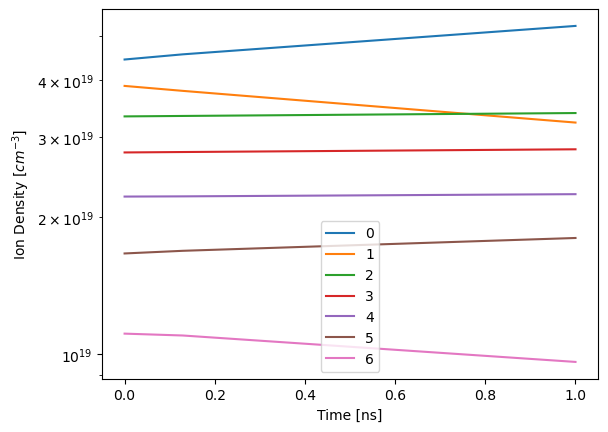

array([2.07567674e-04, 5.16035342e-05, 1.95766537e-04, 6.32588332e-05,
       3.12032168e-04, 4.88372307e-03, 3.29168021e-02])

In [8]:
## TEST B: Saha Equilibrium

def test_saha_eq(end_time, n0, T, print_out=False):
    g_q = np.array([4, 1, 2, 1, 2, 1, 2, 1])
    n = np.zeros((N_levels + 1, ))
    n[:] = np.arange(N_levels + 1, 0, -1)*n0/((N_levels + 1)*(N_levels + 2)/2)
    # n[0] = n0

    bb_photoi_rate_per_level = np.zeros((N_levels, ))

    for level in range(N_levels):
        bb_photoi_rate_per_level[level] = bb_photoi_rate(T, level)

    def dn_dt(t, n):
        rate_matrix = np.zeros((N_levels + 1, N_levels + 1))

        ne = np.dot(n, np.arange(N_levels + 1))
        rate_matrix[0, 0] = -bb_photoi_rate_per_level[0]
        rate_matrix[0, 1] = mat.rr_n(T, 1)*ne*10
        for level in range(1, N_levels):
            rate_matrix[level, level - 1] = bb_photoi_rate_per_level[level - 1]
            if level == 1:
                rate_matrix[level, level] = -mat.rr_n(T, level)*ne*10 - bb_photoi_rate_per_level[level]
            else:
                rate_matrix[level, level] = -mat.rr_n(T, level)*ne - bb_photoi_rate_per_level[level]
            rate_matrix[level, level + 1] = mat.rr_n(T, level + 1)*ne

        rate_matrix[N_levels, N_levels - 1] = bb_photoi_rate_per_level[N_levels - 1]
        rate_matrix[N_levels, N_levels] = -mat.rr_n(T, N_levels)*ne

        return np.matmul(rate_matrix, n)

    out = solve_ivp(dn_dt, (0, end_time), n)

    n_out = out.y[:, -1]

    if print_out:
        print(f"Equilibrium Check for T={T} keV: ")
        plt.figure()
    Dq = np.zeros((N_levels, ))
    ne = np.dot(n_out, np.arange(N_levels + 1))
    for level in range(N_levels):
        saha = 2*g_q[level + 1]/g_q[level]*(2*np.pi*Constants.me_keV*T/(Constants.h**2*Constants.c**2))**1.5*np.exp(-mat.Eth[level]/T)
        Dq[level] = (n_out[level + 1]*ne/n_out[level])/saha
        if print_out:
            print(f"\tLevel {level} Dq: {Dq[level]}")
            print(f"\tSaha Ratio: {saha}")
            print(f"\tIonization level population: {n_out[level]}")
            plt.semilogy(out.t, out.y[level, :], label=str(level))

    if print_out:
        print(f"Total ionization density: {np.sum(n_out)}")
        print(f"Electron density: {ne}")

        plt.legend()
        plt.xlabel("Time [ns]")
        plt.ylabel("Ion Density [$cm^{-3}$]")
        plt.show()

    return Dq

end_time = 1
n0 = 2e20

test_saha_eq(end_time, n0, T_eq, print_out=True)

TEST C: Temperature Sweep of Saha Test

In [ ]:
## TEST C: Temperature Sweep of Saha Test

T_min = 0.01
T_max = 0.1
N_Temps = 10000

Temps = np.linspace(T_min, T_max, N_Temps)

Dq_over_temp = np.zeros((N_levels, N_Temps))

for ind, T in enumerate(Temps):
    Dq_over_temp[:, ind] = test_saha_eq(1/T, n0, T)

for level in range(N_levels):
    plt.plot(Temps, Dq_over_temp[level, :])
plt.xlabel("Temperature [keV]")
plt.ylabel("Dq")
plt.legend([str(level) for level in range(N_levels)])
plt.show()

TEST D: Relaxation of a Non-Planckian Radiation Field

<string>:3: NumbaPerformanceWarning: np.dot() is faster on contiguous arrays, called on (Array(float64, 2, 'A', False, aligned=True), Array(float64, 1, 'C', False, aligned=True))


n_nr is: [5.05992876e+03 2.91400949e+07 6.86514936e+10 7.71560671e+13
 3.95672335e+16 7.70804648e+18 9.67965544e+19 9.54557547e+19]
mesh.ni is initialized to: [[5.05992876e+03 2.91400949e+07 6.86514936e+10 7.71560671e+13
  3.95672335e+16 7.70804648e+18 9.67965544e+19 9.54557547e+19]]
Physical time 0.0202020202020202 ns
Physical time 0.0404040404040404 ns
Physical time 0.06060606060606061 ns
Physical time 0.0808080808080808 ns
Peak density: 3.5092443918083442
Final Particle Count: 110554


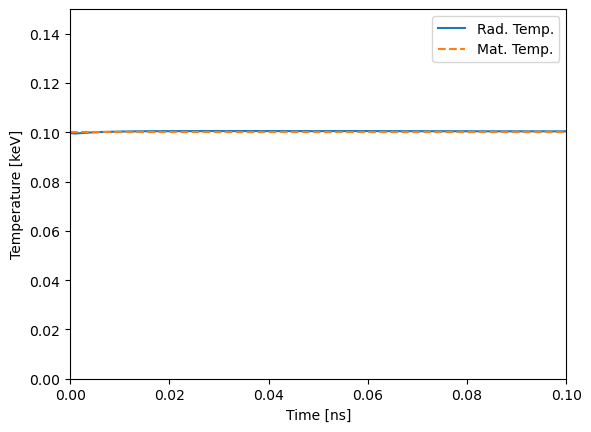

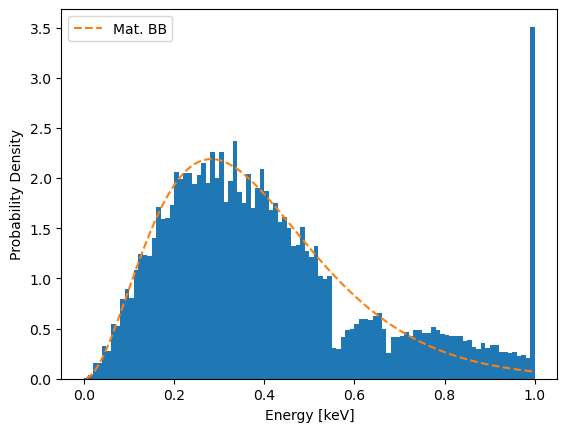

Total ion density: 1.9999999999999964e+20


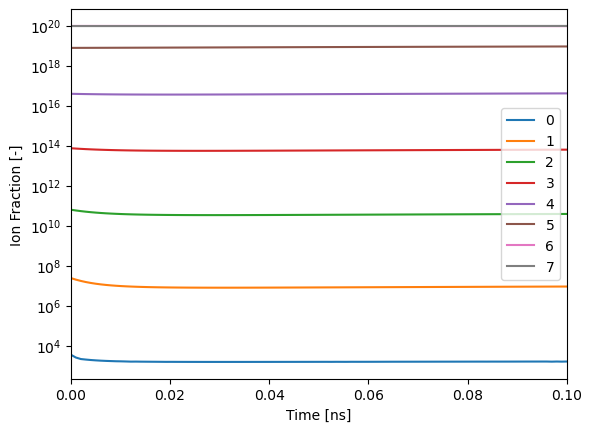

In [15]:
## TEST D: Relaxation of a Non-Planck Radiation Field

# Define an analogue of advance particles
def advance_particles(census, cutoff, mesh, timestep_dist, *varargs):
    if len(varargs) > 0:
        old_mesh = varargs[0]
    else:
        old_mesh = mesh
    
    mesh.reset_iteration()

    # Move particles through timestep
    index = 0
    leaked_energy = 0.0
    while index < len(census):
        p = census[index]
        # For every particle in the system
        outside_bounds = False
        while p.timestep_dist > 0 and not outside_bounds:
            # Use implicit capture to absorb particle and reduce weight, 
            # accounting for photoionization rate
            outside_bounds = mesh.absorb_particle(p, old_mesh, False, dt)
        
        # Reset the distance each particle has traveled 
        p.timestep_dist = timestep_dist
            
        if p.w < cutoff or outside_bounds:
            # If the particle has a weight below the cutoff or leaves the domain remove it
            leaked_energy += Constants.h*p.nu*p.w
            census.pop(index)
            if p.w < cutoff and not outside_bounds:
                mesh.particle_tally[mesh.get_index(p.cell_i, p.cell_k)] -= 1
        else:
            # Move on to the next particle
            index += 1

    # Calculate recombination
    mesh.calculate_rr_rate(old_mesh, dt)

    return census, mesh, leaked_energy

# Define an analogue of MonteCarlo.MonteCarlo_Modular with constant T
def iterative_solver_const_T(census, cutoff, mesh, timestep_dist, tol, max_it, seed):
    # Define error metrics and max iterations
    it = 0
    err = np.ones((3, ))*np.max(n0)
    err_per_it = np.zeros((3, max_it))

    # Copy the initial population which can be reused in each iteration
    population = List()
    for p in census:
        population.append(p.copy())

    # Hold data from previous iterations as convergence criteria
    old_mesh = mesh.copy()
    mesh_previt = mesh.copy()

    while (np.any(abs(err) > tol) and it < max_it):
        census = List()
        for p in population:
            census.append(p.copy())

        # Reset particle tally
        mesh.particle_tally[:] = old_mesh.particle_tally[:]

        # Set the random number seed for generating new particles
        rng = np.random.default_rng(seed)

        census, mesh, leaked_energy = advance_particles(census, cutoff, mesh, timestep_dist, old_mesh)

        # Use previous iteration's temperatures to source particles from recombination
        census = mesh.source_particles_recombination(rng, census, cutoff, dt)

        # Calculate the update to ionization level and associated error
        mesh.update_state(old_mesh, 0.99)

        mesh.Te[mesh.get_index(0, 0)] = T_eq

        err[0] = np.linalg.norm(mesh.ni - mesh_previt.ni)
        err_per_it[0, it] = err[0]
        
        # Calculate the error from flux
        err[1] = np.linalg.norm(mesh.flux - mesh_previt.flux)
        err_per_it[1, it] = err[1]
        
        # Calculate error from material temperature and update
        err[2] = np.linalg.norm(mesh.Te - mesh_previt.Te)
        err_per_it[2, it] = err[2]

        mesh_previt = mesh.copy()

        it += 1

    return census, mesh

dim = 2
end_time = 0.1
dt = 1e-3
N_timesteps = int(end_time/dt)
edges = np.array([0.0, 1.0, 0.0, 1.0])
times = np.linspace(0, end_time, N_timesteps)
dt = end_time/N_timesteps

M = np.array([1, 1], dtype=np.int32)
N_recomb_tot = 1000
N_bremsstrahlung = 0

cutoff = 1e-12
tol = 1e-4
max_it = 100
bcs = np.ones((2*dim, ), dtype=np.int32)

mesh = Mesh(dim, edges, mat.Z, M, mat, n0, N_recomb_tot, N_bremsstrahlung, bcs)
mesh.ni[mesh.get_index(0, 0), :] = n_rc_nr

print(f"n_nr is: {n_rc_nr}")
print(f"mesh.ni is initialized to: {mesh.ni}")

type_photon = Particle(0.1, 0.1, 0.5, np.pi, 800.0, 1.0, 0, 0, 0.0)
census = List.empty_list(typeof(type_photon))

N_source = 10_000
rng = np.random.default_rng()

# Source an initial number of particles
cell_i = 0
cell_k = 0
w0 = Constants.GJ2keV*Constants.a*(T_eq)**4/N_source

for i in range(N_source):
    z_edges = mesh.get_edges_dim(0)
    x_edges = mesh.get_edges_dim(1)

    z_loc = (z_edges[1] - z_edges[0])*rng.random()
    x_loc = (x_edges[1] - x_edges[0])*rng.random()

    mu = 2*rng.random() - 1
    phi = 2*np.pi*rng.random()

    #xi = rng.random()
    #nu = xi/Constants.h

    xi = rng.random(5)
    nu = xsf.sample_blackbody(T_eq, xi)

    #photon = Particle(x_loc, z_loc, mu, phi, nu, w0/xi, cell_i, cell_k, Constants.c*dt)
    photon = Particle(x_loc, z_loc, mu, phi, nu, w0/(Constants.h*nu), cell_i, cell_k, Constants.c*dt)

    census.append(photon)

T_rad = np.zeros((N_timesteps, ))
n_over_time = np.zeros((N_levels + 1, N_timesteps))

print_time = 0.02
print_int = 0.02

for ind, t in enumerate(times):
    census, mesh = iterative_solver_const_T(census, cutoff, mesh, Constants.c*dt, tol, max_it, ind)

    T_rad[ind] = ((mesh.energy_density[mesh.get_index(cell_i, cell_k)]*Constants.keV2GJ)/Constants.a)**0.25
    n_over_time[:, ind] = mesh.ni[mesh.get_index(cell_i, cell_k), :]

    if t > print_time:
        print(f"Physical time {t} ns")
        print_time += print_int

plt.figure()
plt.plot(times, T_rad, c='tab:blue', ls='-', label='Rad. Temp.')
plt.plot(times, np.ones_like(times)*T_eq, c='tab:orange', ls='--', label='Mat. Temp.')
plt.xlabel("Time [ns]")
plt.ylabel("Temperature [keV]")
plt.xlim([0, end_time])
plt.ylim([0, 1.5*T_eq])
plt.legend()

energy_min = 0.01
energy_max = 1
num_energy_bins = 100
energy_bin_edges = np.zeros((num_energy_bins + 1, ))
energy_bin_edges[1:] = np.linspace(energy_min, energy_max, num_energy_bins)
energy_bin_widths = np.diff(energy_bin_edges)
energy_bin_centers = energy_bin_edges[:-1] + energy_bin_widths/2
values = np.zeros_like(energy_bin_centers)

for p in census:
    energy = Constants.h*p.nu
    energy_idx = np.searchsorted(energy_bin_edges, energy) - 1
    if energy >= energy_max:
        energy_idx = num_energy_bins - 1

    values[energy_idx] += p.w*energy/len(census)

blackbody_flux = Constants.GJ2keV*Constants.sigma_SB*T_eq**4

print(f"Peak density: {np.max(values/(np.sum(values)*energy_bin_widths))}")
print(f"Final Particle Count: {len(census)}")

plt.figure()
plt.bar(energy_bin_centers, values/(np.sum(values)*energy_bin_widths), width=energy_bin_widths, align='center')
plt.xlabel("Energy [keV]")
plt.ylabel("Probability Density")
plt.plot(energy_bin_centers, xsf.blackbody(energy_bin_centers/Constants.h, T_eq)/(Constants.h*blackbody_flux), c='tab:orange', ls='--', label='Mat. BB')
plt.legend()
plt.show()

print(f"Total ion density: {np.sum(n_over_time[:, -1])}")

plt.figure()
for level in range(N_levels + 1):
    plt.semilogy(times, n_over_time[level, :], label=str(level))

plt.xlabel("Time [ns]")
plt.ylabel("Ion Fraction [-]")
plt.xlim([0, end_time])
plt.legend()
plt.show()

TEST E: Bremsstrahlung detailed balance for Planckian radiation field

[5.05988859e+03 2.91398945e+07 6.86510942e+10 7.71556999e+13
 3.95670871e+16 7.70802614e+18 9.67964016e+19 9.54557052e+19]
[1.28766698e+21]


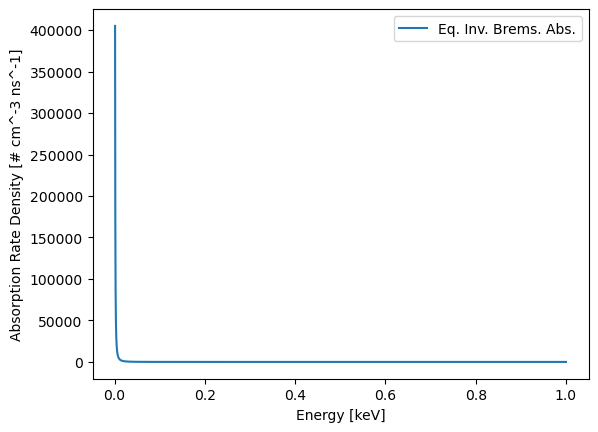

In [41]:
dim = 2
edges = np.array([0.0, 1.0, 0.0, 1.0])
M = np.array([1, 1], dtype=np.int32)
N_recomb_tot = 0
N_bremsstrahlung = 0

bcs = np.ones((2*dim, ), dtype=np.int32)

mesh = Mesh(dim, edges, mat.Z, M, mat, n0, N_recomb_tot, N_bremsstrahlung, bcs)
mesh.ni[mesh.get_index(0, 0), :] = n_rc_nr
mesh.ne[mesh.get_index(0, 0)] = np.dot(n_rc_nr, np.arange(mat.Z + 1))
print(n_rc_nr)
print(mesh.ne)

n_energy_bins = 10_000
energies = np.logspace(-3, 0, n_energy_bins)
ib_abs_rate = np.zeros((n_energy_bins, ))
b_emis_rate = np.zeros((n_energy_bins, ))

for ind, energy in enumerate(energies):
    ib_abs_rate[ind] = xsf.blackbody(energy/Constants.h, T_eq)/(Constants.h*energy)*mat.ibrem_xs(mesh, mesh.get_index(0, 0), energy/Constants.h)

plt.plot(energies, ib_abs_rate, label='Eq. Inv. Brems. Abs.')
plt.xlabel("Energy [keV]")
plt.ylabel("Absorption Rate Density [# cm^-3 ns^-1]")
plt.legend()
plt.show()

TEST F: Relaxation of a Non-Planck Radiation Field - Bremsstrahlung Only

n_nr is: [5.05988859e+03 2.91398945e+07 6.86510942e+10 7.71556999e+13
 3.95670871e+16 7.70802614e+18 9.67964016e+19 9.54557052e+19]
mesh.ni is initialized to: [[5.05988859e+03 2.91398945e+07 6.86510942e+10 7.71556999e+13
  3.95670871e+16 7.70802614e+18 9.67964016e+19 9.54557052e+19]]
n_e is: [1.28766698e+21]
Physical time 0.0202020202020202 ns
Physical time 0.0404040404040404 ns
Physical time 0.06060606060606061 ns
Physical time 0.0808080808080808 ns
Peak density: 2.334530040976261
Final Particle Count: 109972


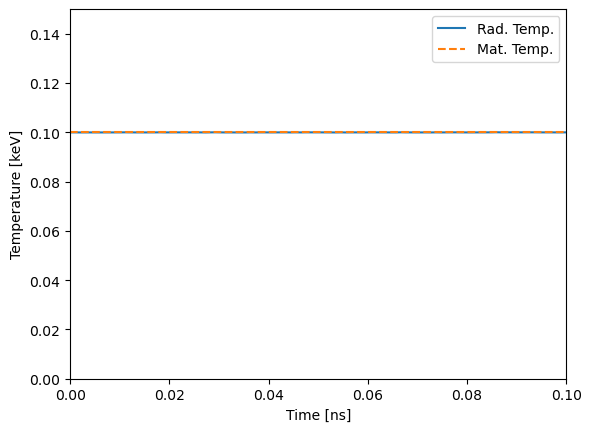

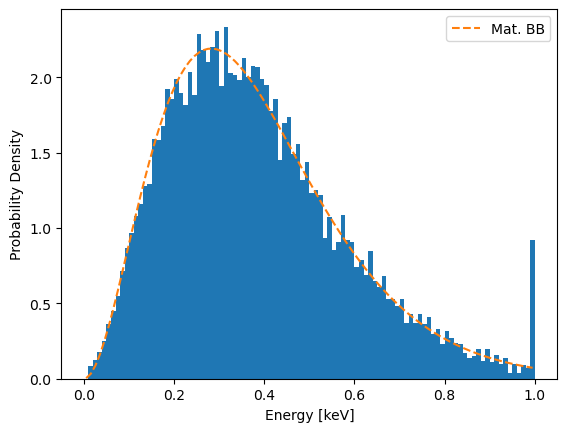

Total ion density: 1.99999777299079e+20


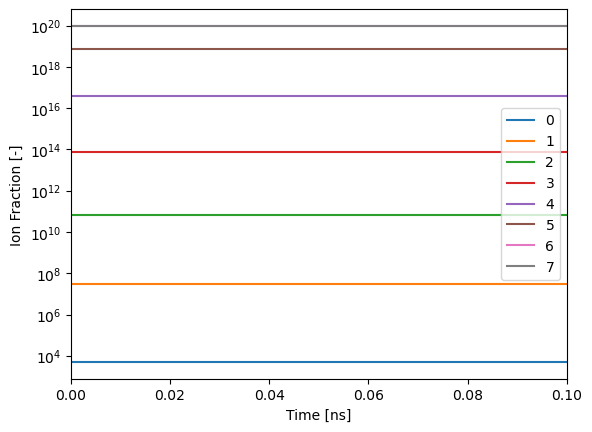

In [39]:
## TEST F: Relaxation of a Non-Planck Radiation Field - Bremsstrahlung Radiation only

# Define an analogue of advance particles
def advance_particles(census, cutoff, mesh, timestep_dist, *varargs):
    if len(varargs) > 0:
        old_mesh = varargs[0]
    else:
        old_mesh = mesh
    
    mesh.reset_iteration()

    # Move particles through timestep
    index = 0
    leaked_energy = 0.0
    while index < len(census):
        p = census[index]
        # For every particle in the system
        outside_bounds = False
        while p.timestep_dist > 0 and not outside_bounds:
            # Use implicit capture to absorb particle and reduce weight, 
            # accounting for photoionization rate
            outside_bounds = mesh.absorb_particle(p, old_mesh, True, dt)
        
        # Reset the distance each particle has traveled 
        p.timestep_dist = timestep_dist
            
        if p.w < cutoff or outside_bounds:
            # If the particle has a weight below the cutoff or leaves the domain remove it
            leaked_energy += Constants.h*p.nu*p.w
            census.pop(index)
            if p.w < cutoff and not outside_bounds:
                mesh.particle_tally[mesh.get_index(p.cell_i, p.cell_k)] -= 1
        else:
            # Move on to the next particle
            index += 1

    # Calculate recombination
    #mesh.calculate_rr_rate(old_mesh, dt)

    return census, mesh, leaked_energy

# Define an analogue of MonteCarlo.MonteCarlo_Modular with constant T
def iterative_solver_const_T(census, cutoff, mesh, timestep_dist, tol, max_it, seed):
    # Define error metrics and max iterations
    it = 0
    err = np.ones((3, ))*np.max(n0)
    err_per_it = np.zeros((3, max_it))

    # Copy the initial population which can be reused in each iteration
    population = List()
    for p in census:
        population.append(p.copy())

    # Hold data from previous iterations as convergence criteria
    old_mesh = mesh.copy()
    mesh_previt = mesh.copy()

    while (np.any(abs(err) > tol) and it < max_it):
        census = List()
        for p in population:
            census.append(p.copy())

        # Reset particle tally
        mesh.particle_tally[:] = old_mesh.particle_tally[:]

        # Set the random number seed for generating new particles
        rng = np.random.default_rng(seed)

        census, mesh, leaked_energy = advance_particles(census, cutoff, mesh, timestep_dist, old_mesh)

        # Use previous iteration's temperatures to source particles from bremsstrahlung
        census = mesh.source_particles_bremsstrahlung(rng, census, cutoff, dt)

        # Calculate the update to ionization level and associated error
        mesh.update_state(old_mesh, 0.99)

        mesh.Te[mesh.get_index(0, 0)] = T_eq

        err[0] = np.linalg.norm(mesh.ni - mesh_previt.ni)
        err_per_it[0, it] = err[0]
        
        # Calculate the error from flux
        err[1] = np.linalg.norm(mesh.flux - mesh_previt.flux)
        err_per_it[1, it] = err[1]
        
        # Calculate error from material temperature and update
        err[2] = np.linalg.norm(mesh.Te - mesh_previt.Te)
        err_per_it[2, it] = err[2]

        mesh_previt = mesh.copy()

        it += 1

    return census, mesh

dim = 2
end_time = 0.1
dt = 1e-3
N_timesteps = int(end_time/dt)
edges = np.array([0.0, 1.0, 0.0, 1.0])
times = np.linspace(0, end_time, N_timesteps)
dt = end_time/N_timesteps

M = np.array([1, 1], dtype=np.int32)
N_recomb_tot = 0
N_bremsstrahlung = 1000

cutoff = 1e-12
tol = 1e-4
max_it = 100
bcs = np.ones((2*dim, ), dtype=np.int32)

mesh = Mesh(dim, edges, mat.Z, M, mat, n0, N_recomb_tot, N_bremsstrahlung, bcs)
mesh.ni[mesh.get_index(0, 0), :] = n_rc_nr
mesh.ne[mesh.get_index(0, 0)] = np.dot(n_rc_nr, np.arange(mat.Z + 1))

print(f"n_nr is: {n_rc_nr}")
print(f"mesh.ni is initialized to: {mesh.ni}")
print(f"n_e is: {mesh.ne}")

type_photon = Particle(0.1, 0.1, 0.5, np.pi, 800.0, 1.0, 0, 0, 0.0)
census = List.empty_list(typeof(type_photon))

N_source = 10_000
rng = np.random.default_rng()

# Source an initial number of particles
cell_i = 0
cell_k = 0
w0 = Constants.GJ2keV*Constants.a*(T_eq)**4/N_source

for i in range(N_source):
    z_edges = mesh.get_edges_dim(0)
    x_edges = mesh.get_edges_dim(1)

    z_loc = (z_edges[1] - z_edges[0])*rng.random()
    x_loc = (x_edges[1] - x_edges[0])*rng.random()

    mu = 2*rng.random() - 1
    phi = 2*np.pi*rng.random()

    #xi = rng.random()
    #nu = xi/Constants.h

    xi = rng.random(5)
    nu = xsf.sample_blackbody(T_eq, xi)

    #photon = Particle(x_loc, z_loc, mu, phi, nu, w0/xi, cell_i, cell_k, Constants.c*dt)
    photon = Particle(x_loc, z_loc, mu, phi, nu, w0/(Constants.h*nu), cell_i, cell_k, Constants.c*dt)

    census.append(photon)

T_rad = np.zeros((N_timesteps, ))
n_over_time = np.zeros((N_levels + 1, N_timesteps))

print_time = 0.02
print_int = 0.02

for ind, t in enumerate(times):
    census, mesh = iterative_solver_const_T(census, cutoff, mesh, Constants.c*dt, tol, max_it, ind)

    T_rad[ind] = ((mesh.energy_density[mesh.get_index(cell_i, cell_k)]*Constants.keV2GJ)/Constants.a)**0.25
    n_over_time[:, ind] = mesh.ni[mesh.get_index(cell_i, cell_k), :]

    if t > print_time:
        print(f"Physical time {t} ns")
        print_time += print_int

plt.figure()
plt.plot(times, T_rad, c='tab:blue', ls='-', label='Rad. Temp.')
plt.plot(times, np.ones_like(times)*T_eq, c='tab:orange', ls='--', label='Mat. Temp.')
plt.xlabel("Time [ns]")
plt.ylabel("Temperature [keV]")
plt.xlim([0, end_time])
plt.ylim([0, 1.5*T_eq])
plt.legend()

energy_min = 0.01
energy_max = 1
num_energy_bins = 100
energy_bin_edges = np.zeros((num_energy_bins + 1, ))
energy_bin_edges[1:] = np.linspace(energy_min, energy_max, num_energy_bins)
energy_bin_widths = np.diff(energy_bin_edges)
energy_bin_centers = energy_bin_edges[:-1] + energy_bin_widths/2
values = np.zeros_like(energy_bin_centers)

for p in census:
    energy = Constants.h*p.nu
    energy_idx = np.searchsorted(energy_bin_edges, energy) - 1
    if energy >= energy_max:
        energy_idx = num_energy_bins - 1

    values[energy_idx] += p.w*energy/len(census)

blackbody_flux = Constants.GJ2keV*Constants.sigma_SB*T_eq**4

print(f"Peak density: {np.max(values/(np.sum(values)*energy_bin_widths))}")
print(f"Final Particle Count: {len(census)}")

plt.figure()
plt.bar(energy_bin_centers, values/(np.sum(values)*energy_bin_widths), width=energy_bin_widths, align='center')
plt.xlabel("Energy [keV]")
plt.ylabel("Probability Density")
plt.plot(energy_bin_centers, xsf.blackbody(energy_bin_centers/Constants.h, T_eq)/(Constants.h*blackbody_flux), c='tab:orange', ls='--', label='Mat. BB')
plt.legend()
plt.show()

print(f"Total ion density: {np.sum(n_over_time[:, -1])}")

plt.figure()
for level in range(N_levels + 1):
    plt.semilogy(times, n_over_time[level, :], label=str(level))

plt.xlabel("Time [ns]")
plt.ylabel("Ion Fraction [-]")
plt.xlim([0, end_time])
plt.legend()
plt.show()